In [1]:
import pandas as pd

train_df = pd.read_csv(
    "../dataset/tweet_eval_train.csv",
    encoding="utf-8"
)

validation_df = pd.read_csv(
    "../dataset/tweet_eval_validation.csv",
    encoding="utf-8"
)

test_df = pd.read_csv(
    "../dataset/tweet_eval_test.csv",
    encoding="utf-8"
)

print("Training:", train_df.shape)
print("Validation:", validation_df.shape)
print("Testing:", test_df.shape)

Training: (45615, 3)
Validation: (2000, 3)
Testing: (12284, 3)


In [2]:
train_df.head(10)

,text,label,sentiment
0,"""QT @user In the original draft of the 7th boo...",2,positive
1,"""Ben Smith / Smith (concussion) remains out of...",1,neutral
2,Sorry bout the stream last night I crashed out...,1,neutral
3,Chase Headley's RBI double in the 8th inning o...,1,neutral
4,@user Alciato: Bee will invest 150 million in ...,2,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,2,positive
6,"""\"""""""" SOUL TRAIN\"""""""" OCT 27 HALLOWEEN SPECIA...",2,positive
7,So disappointed in wwe summerslam! I want to s...,0,negative
8,"""This is the last Sunday w/o football .....,NF...",2,positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,1,neutral


In [3]:
print(train_df["sentiment"].value_counts())

sentiment
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64


<Axes: title={'center': 'Training Dataset Sentiment Distribution'}, xlabel='sentiment'>

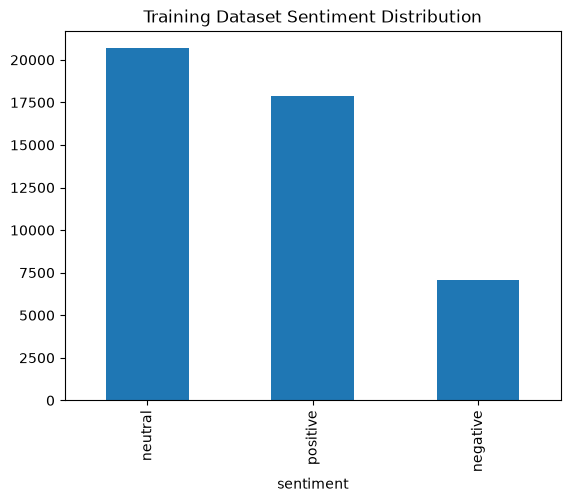

In [4]:
train_df["sentiment"].value_counts().plot(
    kind="bar",
    title="Training Dataset Sentiment Distribution"
)

In [5]:
import emoji

def extract_emojis(text):
    return [
        item["emoji"]
        for item in emoji.emoji_list(str(text))
    ]

In [6]:
test_text = "I absolutely love this 😍❤️🔥"

print(extract_emojis(test_text))

['😍', '❤️', '🔥']


In [7]:
train_df["emojis"] = train_df["text"].apply(extract_emojis)

train_df["emoji_count"] = train_df["emojis"].apply(len)

In [8]:
train_df[["text", "emojis", "emoji_count", "sentiment"]].head(20)

,text,emojis,emoji_count,sentiment
0,"""QT @user In the original draft of the 7th boo...",[],0,positive
1,"""Ben Smith / Smith (concussion) remains out of...",[],0,neutral
2,Sorry bout the stream last night I crashed out...,[],0,neutral
3,Chase Headley's RBI double in the 8th inning o...,[],0,neutral
4,@user Alciato: Bee will invest 150 million in ...,[],0,positive
5,@user LIT MY MUM 'Kerry the louboutins I wonde...,[],0,positive
6,"""\"""""""" SOUL TRAIN\"""""""" OCT 27 HALLOWEEN SPECIA...",[],0,positive
7,So disappointed in wwe summerslam! I want to s...,[],0,negative
8,"""This is the last Sunday w/o football .....,NF...",[],0,positive
9,@user @user CENA & AJ sitting in a tree K-I-S-...,[],0,neutral


In [9]:
emoji_tweets = (train_df["emoji_count"] > 0).sum()

total_tweets = len(train_df)

print("Total tweets:", total_tweets)
print("Tweets containing emojis:", emoji_tweets)
print(
    "Percentage containing emojis:",
    round((emoji_tweets / total_tweets) * 100, 2),
    "%"
)

Total tweets: 45615
Tweets containing emojis: 0
Percentage containing emojis: 0.0 %


In [10]:
import pandas as pd
import emoji

train = pd.read_csv("../dataset/tweet_eval_train.csv")
test = pd.read_csv("../dataset/tweet_eval_test.csv")
validation = pd.read_csv("../dataset/tweet_eval_validation.csv")

def count_emojis(text):
    return len(emoji.emoji_list(str(text)))

for name, df in [
    ("TRAIN", train),
    ("TEST", test),
    ("VALIDATION", validation)
]:
    counts = df["text"].apply(count_emojis)

    print("\n", name)
    print("Total:", len(df))
    print("Emoji tweets:", (counts > 0).sum())
    print("Total emojis:", counts.sum())


 TRAIN
Total: 45615
Emoji tweets: 0
Total emojis: 0

 TEST
Total: 12284
Emoji tweets: 809
Total emojis: 1579

 VALIDATION
Total: 2000
Emoji tweets: 0
Total emojis: 0


In [11]:
print("TRAIN COLUMNS:")
print(train.columns)

print("\nTRAIN LABELS:")
print(train["sentiment"].value_counts())

print("\nTEST COLUMNS:")
print(test.columns)

print("\nTEST LABELS:")
print(test["sentiment"].value_counts())

print("\nVALIDATION COLUMNS:")
print(validation.columns)

print("\nVALIDATION LABELS:")
print(validation["sentiment"].value_counts())

TRAIN COLUMNS:
Index(['text', 'label', 'sentiment'], dtype='str')

TRAIN LABELS:
sentiment
neutral     20673
positive    17849
negative     7093
Name: count, dtype: int64

TEST COLUMNS:
Index(['text', 'label', 'sentiment'], dtype='str')

TEST LABELS:
sentiment
neutral     5937
negative    3972
positive    2375
Name: count, dtype: int64

VALIDATION COLUMNS:
Index(['text', 'label', 'sentiment'], dtype='str')

VALIDATION LABELS:
sentiment
neutral     869
positive    819
negative    312
Name: count, dtype: int64


In [12]:
emoji_test = test[
    test["text"].apply(lambda x: len(emoji.emoji_list(str(x))) > 0)
]

print("Number of emoji tweets:", len(emoji_test))

display(emoji_test[["text", "sentiment"]].head(30))

Number of emoji tweets: 809


,text,sentiment
6,How many more days until opening day? 😩,neutral
12,#onedirection #harrystyles cute little dance 😉,positive
15,@user ohhh ok i see 🤔 what if u have medical m...,neutral
23,The United Nations Headquarters in New York #u...,neutral
63,idk where to start after my intro. im writing ...,neutral
72,@user ain't that how y'all got Tim Duncan? 🤔,neutral
81,#NoDAPL #CorporateGreed #corporations are #evi...,negative
82,@user it's free with insurance because of Obam...,negative
120,After finally watching the whole of #Fantastic...,positive
126,Omg I love Jill Scott why am I just now watchi...,positive


In [13]:
emoji_test.groupby("sentiment").size()

sentiment
negative    187
neutral     267
positive    355
dtype: int64

In [14]:
emoji_test["text"].apply(
    lambda x: emoji.emoji_list(str(x))
).explode().head(20)

6      {'match_start': 38, 'match_end': 39, 'emoji': ...
12     {'match_start': 45, 'match_end': 46, 'emoji': ...
15     {'match_start': 20, 'match_end': 21, 'emoji': ...
23     {'match_start': 72, 'match_end': 74, 'emoji': ...
63     {'match_start': 96, 'match_end': 98, 'emoji': ...
72     {'match_start': 43, 'match_end': 44, 'emoji': ...
81     {'match_start': 138, 'match_end': 139, 'emoji'...
82     {'match_start': 81, 'match_end': 82, 'emoji': ...
120    {'match_start': 106, 'match_end': 107, 'emoji'...
126    {'match_start': 64, 'match_end': 65, 'emoji': ...
128    {'match_start': 83, 'match_end': 84, 'emoji': ...
150    {'match_start': 40, 'match_end': 41, 'emoji': ...
151    {'match_start': 128, 'match_end': 129, 'emoji'...
151    {'match_start': 130, 'match_end': 131, 'emoji'...
151    {'match_start': 131, 'match_end': 132, 'emoji'...
165    {'match_start': 120, 'match_end': 121, 'emoji'...
183    {'match_start': 122, 'match_end': 123, 'emoji'...
229    {'match_start': 69, 'mat

In [15]:
import pandas as pd
import emoji


def count_emojis(text):
    return len([
        char for char in text
        if char in emoji.EMOJI_DATA
    ])


train = pd.read_csv(
    "../dataset/final_train.csv",
    encoding="utf-8"
)

validation = pd.read_csv(
    "../dataset/final_validation.csv",
    encoding="utf-8"
)

test = pd.read_csv(
    "../dataset/final_test.csv",
    encoding="utf-8"
)


for name, df in [
    ("TRAIN", train),
    ("VALIDATION", validation),
    ("TEST", test)
]:

    df["emoji_count"] = df["text"].apply(count_emojis)

    emoji_tweets = (df["emoji_count"] > 0).sum()
    total_emojis = df["emoji_count"].sum()

    print("\n==============================")
    print(name)
    print("==============================")

    print("Total tweets:", len(df))
    print("Emoji tweets:", emoji_tweets)
    print("Total emojis:", total_emojis)
    print(
        "Emoji percentage:",
        round(emoji_tweets / len(df) * 100, 2),
        "%"
    )


TRAIN
Total tweets: 45606
Emoji tweets: 17
Total emojis: 25
Emoji percentage: 0.04 %

VALIDATION
Total tweets: 2000
Emoji tweets: 0
Total emojis: 0
Emoji percentage: 0.0 %

TEST
Total tweets: 12284
Emoji tweets: 794
Total emojis: 1637
Emoji percentage: 6.46 %


In [16]:
emoji_train = train[train["emoji_count"] > 0].copy()

print("Emoji tweets by sentiment:")
print(
    emoji_train["sentiment"].value_counts()
)

Emoji tweets by sentiment:
sentiment
positive    7
negative    7
neutral     3
Name: count, dtype: int64


In [17]:
print("\nEmoji tweets:")
print(
    emoji_train[
        ["text", "sentiment", "emoji_count"]
    ].head(20).to_string(index=False)
)


Emoji tweets:
                              text sentiment  emoji_count
I absolutely love this product 😍❤️  positive            2
                      It is okay 🙂   neutral            1
           The movie was average 😐   neutral            1
              Very disappointing 😞  negative            1
           Worst experience ever 😭  negative            1
       This service is horrible 😡👎  negative            2
        I am so happy with this! 🥰  positive            1
        I don't like this at all 😒  negative            1
                    Great work! 👍😊  positive            2
        Nothing special about it 😶   neutral            1
     I really enjoyed this movie 😍  positive            1
                This is terrible 😡  negative            1
        Absolutely fantastic! 😍❤️🔥  positive            3
            Very bad experience 😡😭  negative            2
            I hate this product 😠💔  negative            2
               This is amazing! 😊🔥  positive            2

In [19]:
from collections import Counter


def extract_emojis(text):
    return [
        char for char in text
        if char in emoji.EMOJI_DATA
    ]


all_emojis = []

for text in train["text"]:
    all_emojis.extend(
        extract_emojis(text)
    )


emoji_counter = Counter(all_emojis)

print("Top emojis:")

for em, count in emoji_counter.most_common(20):
    print(em, ":", count)

Top emojis:
😍 : 3
❤ : 3
😡 : 3
😭 : 2
😊 : 2
🔥 : 2
🙂 : 1
😐 : 1
😞 : 1
👎 : 1
🥰 : 1
😒 : 1
👍 : 1
😶 : 1
😠 : 1
💔 : 1


In [20]:
from collections import defaultdict

emoji_sentiment = defaultdict(Counter)

for _, row in train.iterrows():

    emojis = extract_emojis(row["text"])

    for em in emojis:
        emoji_sentiment[em][row["sentiment"]] += 1


rows = []

for em, sentiments in emoji_sentiment.items():

    rows.append({
        "emoji": em,
        "positive": sentiments["positive"],
        "negative": sentiments["negative"],
        "neutral": sentiments["neutral"],
        "total": sum(sentiments.values())
    })


emoji_sentiment_df = pd.DataFrame(rows)

emoji_sentiment_df = emoji_sentiment_df.sort_values(
    "total",
    ascending=False
)


print(
    emoji_sentiment_df.head(20).to_string(
        index=False
    )
)

emoji  positive  negative  neutral  total
    😍         3         0        0      3
    ❤         3         0        0      3
    😡         0         3        0      3
    😭         0         2        0      2
    🔥         2         0        0      2
    😊         2         0        0      2
    😐         0         0        1      1
    🙂         0         0        1      1
    👎         0         1        0      1
    😞         0         1        0      1
    😒         0         1        0      1
    🥰         1         0        0      1
    👍         1         0        0      1
    😶         0         0        1      1
    😠         0         1        0      1
    💔         0         1        0      1


In [ ]:
emoji_sentiment_df.to_csv(
    "../results/emoji_sentiment_distribution.csv",
    index=False,
    encoding="utf-8"
)

print("Emoji sentiment analysis saved.")


Emoji sentiment analysis saved.


In [22]:
import pandas as pd
import emoji

# Load final datasets
train = pd.read_csv(
    "../dataset/final_train.csv",
    encoding="utf-8"
)

validation = pd.read_csv(
    "../dataset/final_validation.csv",
    encoding="utf-8"
)

test = pd.read_csv(
    "../dataset/final_test.csv",
    encoding="utf-8"
)

print("TRAIN SHAPE:", train.shape)
print("VALIDATION SHAPE:", validation.shape)
print("TEST SHAPE:", test.shape)

print("\nTRAIN COLUMNS:")
print(train.columns)

print("\nVALIDATION COLUMNS:")
print(validation.columns)

print("\nTEST COLUMNS:")
print(test.columns)

TRAIN SHAPE: (45606, 2)
VALIDATION SHAPE: (2000, 2)
TEST SHAPE: (12284, 2)

TRAIN COLUMNS:
Index(['text', 'sentiment'], dtype='str')

VALIDATION COLUMNS:
Index(['text', 'sentiment'], dtype='str')

TEST COLUMNS:
Index(['text', 'sentiment'], dtype='str')


In [23]:
import pandas as pd
import emoji

# Load final training dataset
train = pd.read_csv(
    "../dataset/final_train.csv",
    encoding="utf-8"
)

# Function to extract emojis
def extract_emojis(text):
    return [
        char for char in text
        if char in emoji.EMOJI_DATA
    ]

# Find emojis
train["emoji_list"] = train["text"].apply(extract_emojis)
train["emoji_count"] = train["emoji_list"].apply(len)

# Statistics
emoji_tweets = (train["emoji_count"] > 0).sum()
total_emojis = train["emoji_count"].sum()

print("Total training tweets:", len(train))
print("Training tweets containing emojis:", emoji_tweets)
print("Total emojis in training:", total_emojis)

print(
    "Percentage of training tweets containing emojis:",
    round((emoji_tweets / len(train)) * 100, 2),
    "%"
)

Total training tweets: 45606
Training tweets containing emojis: 17
Total emojis in training: 25
Percentage of training tweets containing emojis: 0.04 %


In [24]:
emoji_examples = train[
    train["emoji_count"] > 0
][
    ["text", "emoji_list", "sentiment", "emoji_count"]
]

print(
    emoji_examples.head(20).to_string(index=False)
)


                              text emoji_list sentiment  emoji_count
I absolutely love this product 😍❤️     [😍, ❤]  positive            2
                      It is okay 🙂        [🙂]   neutral            1
           The movie was average 😐        [😐]   neutral            1
              Very disappointing 😞        [😞]  negative            1
           Worst experience ever 😭        [😭]  negative            1
       This service is horrible 😡👎     [😡, 👎]  negative            2
        I am so happy with this! 🥰        [🥰]  positive            1
        I don't like this at all 😒        [😒]  negative            1
                    Great work! 👍😊     [👍, 😊]  positive            2
        Nothing special about it 😶        [😶]   neutral            1
     I really enjoyed this movie 😍        [😍]  positive            1
                This is terrible 😡        [😡]  negative            1
        Absolutely fantastic! 😍❤️🔥  [😍, ❤, 🔥]  positive            3
            Very bad experience 😡😭

In [25]:
print("Emoji tweets by sentiment:")
print(
    emoji_examples["sentiment"].value_counts()
)

Emoji tweets by sentiment:
sentiment
positive    7
negative    7
neutral     3
Name: count, dtype: int64


In [26]:
emoji_train = train[
    train["emoji_count"] > 0
][
    ["text", "sentiment", "emoji_count"]
]

print("Number of emoji tweets:", len(emoji_train))
print("Total emojis:", emoji_train["emoji_count"].sum())

print("\nEmoji training examples:")
print(
    emoji_train.to_string(index=False)
)

Number of emoji tweets: 17
Total emojis: 25

Emoji training examples:
                              text sentiment  emoji_count
I absolutely love this product 😍❤️  positive            2
                      It is okay 🙂   neutral            1
           The movie was average 😐   neutral            1
              Very disappointing 😞  negative            1
           Worst experience ever 😭  negative            1
       This service is horrible 😡👎  negative            2
        I am so happy with this! 🥰  positive            1
        I don't like this at all 😒  negative            1
                    Great work! 👍😊  positive            2
        Nothing special about it 😶   neutral            1
     I really enjoyed this movie 😍  positive            1
                This is terrible 😡  negative            1
        Absolutely fantastic! 😍❤️🔥  positive            3
            Very bad experience 😡😭  negative            2
            I hate this product 😠💔  negative            2
  

In [27]:
print("\nEmoji tweets by sentiment:")
print(
    emoji_train["sentiment"].value_counts()
)


Emoji tweets by sentiment:
sentiment
positive    7
negative    7
neutral     3
Name: count, dtype: int64
